# Figure 05 · Rotation · kết quả tự train

14 dataset,4 model,2 mức loại biến,2 trạng thái xoay,224ô/560fit. Tham số công bố chọn bằng validation; đủ original auto seeds.

Notebook này **đọc output thật đã audit rồi tính trung bình/vẽ lại**,không fit model hay chạy HPO.
Đây là accuracy thô của nhóm,không phải đường chuẩn hóa lấy từ paper.
Ba bộ numeric đại diện có thể kiểm tra offline ở `../results/numeric/`.
Xem notebook phân tích kết quả tác giả riêng tại `../../notebooks/`.

In [1]:
from pathlib import Path
import sys, json, io
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'reproduce/results/mechanism_cells.csv').exists())
sys.path.insert(0, str(ROOT / 'reproduce/scripts'))
from plots import cells, plot, means


In [2]:
frame = cells('rotation')
assert len(frame) == 224
display(frame[['dataset','model','condition','required_seeds','test_accuracy_mean','validation_accuracy_mean']].head(12))

,dataset,model,condition,required_seeds,test_accuracy_mean,validation_accuracy_mean
28,electricity,ft_transformer,"[0.0, false]",[0],0.804184,0.808593
29,credit,ft_transformer,"[0.5, true]","[0, 1]",0.740745,0.751490
30,credit,ft_transformer,"[0.0, true]","[0, 1]",0.771489,0.774081
31,pol,ft_transformer,"[0.5, true]","[0, 1, 2]",0.981744,0.983094
32,MagicTelescope,ft_transformer,"[0.0, false]","[0, 1, 2]",0.852669,0.849266
33,pol,ft_transformer,"[0.5, false]","[0, 1, 2]",0.939408,0.949651
34,pol,ft_transformer,"[0.0, true]","[0, 1, 2]",0.981272,0.984564
35,electricity,ft_transformer,"[0.5, true]",[0],0.794200,0.792672
36,electricity,ft_transformer,"[0.5, false]",[0],0.799970,0.793374
37,MagicTelescope,ft_transformer,"[0.5, true]","[0, 1, 2]",0.842349,0.845664


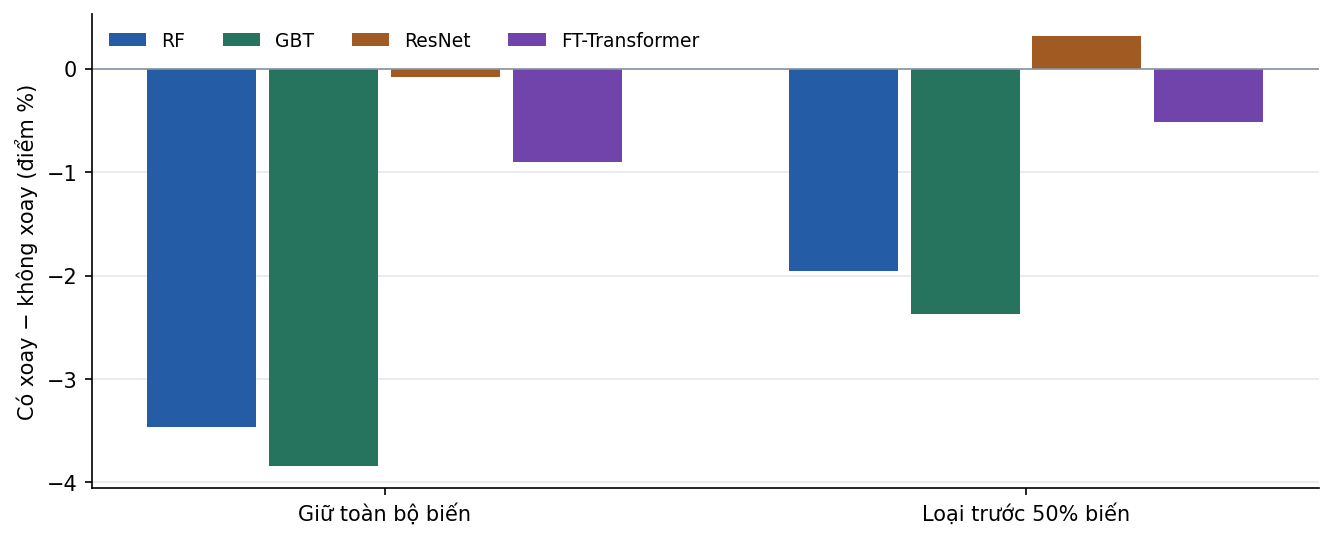

In [3]:
fig = plot('rotation')
buf = io.BytesIO()
fig.savefig(buf, format='png', dpi=150, bbox_inches='tight')
display(Image(data=buf.getvalue()))

## Một fit gốc đại diện
Nhãn,dự đoán và rowID được lưu;số liệu dưới là một seed,không thay cho toàn bộ grid.

In [4]:
examples = json.loads((ROOT / 'reproduce/results/sample_fits.json').read_bytes())
example = next(e for e in examples if e['id'] == 'rotation')
display({k: example[k] for k in ['dataset','model','seed','condition','metrics','source_record']})

{'dataset': 'electricity',
 'model': 'rf',
 'seed': 0,
 'condition': [0.0, False],
 'metrics': {'train': {'accuracy': 1.0,
   'confusion_matrix': [[5011, 0], [0, 4989]]},
  'validation': {'accuracy': 0.8090611098103488,
   'confusion_matrix': [[3462, 813], [818, 3449]]},
  'test': {'accuracy': 0.8110074252458358,
   'confusion_matrix': [[8109, 1842], [1925, 8056]]}},
 'source_record': 81735}

## Nếu muốn train lại
Đọc `../training/README.md` rồi dùng lệnh thủ công với Python3.8. Run All của notebook này luôn chỉ phân tích dữ liệu đã lưu;không gửi job.